# Fase 2 – Modelo: ¿dengue o no dengue según los síntomas?

Este notebook **explica y visualiza** el entrenamiento. La lógica vive en `src/train.py` y
`src/preprocesamiento.py`; aquí se importan esas mismas funciones, así que el notebook y el script siempre dan los mismos resultados.
El modelo oficial (`models/modelo.pkl`) se genera con:

```bash
python -m src.train
```

### Resumen de decisiones (aprobadas en la Fase 1)
| Decisión | Elección | Por qué |
|---|---|---|
| Variable objetivo | 1 = dengue confirmado, 0 = descartado (`ajuste_ = 6`); se excluyen los "probables" | Solo se usan casos con etiqueta cierta |
| Variables de entrada | grupo de edad, sexo y 10 síntomas reportables | Lo que un paciente puede llenar en un formulario |
| Excluidas | fiebre (constante), laboratorio/examen (plaquetas, hematocrito, hepatomegalia…), fuga (choque, daño de órgano, clasificación final, hospitalización…) | Sin información, no reportables o con fuga de información |

In [1]:
import sys
sys.path.insert(0, "..")  # raíz del proyecto, para importar el paquete src

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, precision_score, recall_score

from src.preprocesamiento import FEATURES, preparar_datos
from src.train import METRICAS, entrenar

pd.set_option("display.precision", 3)

## 1. Datos y limpieza
- Síntomas: SIVIGILA usa **1 = Sí, 2 = No**. Se normalizan a **1/0** con `a_binario()`. Cualquier valor no
  reconocido queda como nulo.
- Nulos: se imputan con el **valor más frecuente** *dentro* del pipeline. Así la imputación se aprende solo con los
  datos de entrenamiento (sin fuga de información) y la app web la aplica igual a un formulario incompleto.
- Edad y sexo: codificación **one-hot**. Un modelo lineal no debe tratar el grupo de edad "60+" como si fuera "6 veces 0-5".

In [2]:
X, y, fechas = preparar_datos()
print(f"Casos: {len(X):,}  |  dengue: {y.mean():.1%}  |  variables: {FEATURES}")
print("\nNulos por variable:\n", X.isna().sum().to_string())
X.head()

Casos: 19,340  |  dengue: 68.3%  |  variables: ['grupo_edad', 'sexo', 'cefalea', 'dolor_retroocular', 'mialgias', 'artralgia', 'erupcion', 'dolor_abdominal', 'vomito', 'diarrea', 'somnolencia', 'sangrado_mucosas']

Nulos por variable:
 grupo_edad           0
sexo                 0
cefalea              0
dolor_retroocular    0
mialgias             0
artralgia            0
erupcion             0
dolor_abdominal      0
vomito               0
diarrea              0
somnolencia          0
sangrado_mucosas     0


,grupo_edad,sexo,cefalea,dolor_retroocular,mialgias,artralgia,erupcion,dolor_abdominal,vomito,diarrea,somnolencia,sangrado_mucosas
0,12-17,F,1.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0
1,29-59,F,1.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
2,12-17,M,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0
3,29-59,M,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
5,29-59,M,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


## 2. Entrenamiento y comparación de modelos
- **Partición:** 80 % entrenamiento / 20 % test, **estratificada** (misma proporción de dengue en ambos). El test
  no se usa hasta el final.
- **Validación cruzada estratificada de 5 pliegues** sobre el 80 %. Cada modelo se entrena 5 veces con
  distintas porciones y se promedian las métricas. Es más confiable que una sola partición.
- **Desbalance (68/32):** `class_weight="balanced"` da más peso a los errores en la clase minoritaria. No crea datos
  sintéticos (SMOTE) ni elimina datos (submuestreo).
- **Modelos:**
  1. *Regresión Logística*: lineal, interpretable, sirve como línea base.
  2. *Random Forest*: muchos árboles por votación; captura interacciones entre síntomas.
  3. *Gradient Boosting* (`HistGradientBoostingClassifier`): árboles secuenciales que corrigen los errores del
     anterior. Es la implementación de scikit-learn, equivalente a XGBoost, y no agrega otra dependencia al despliegue.

In [3]:
artefacto, ctx = entrenar(guardar=False)

Datos: 19,340 casos (68.3% dengue) | train 15,472 | test 3,868



Validación cruzada (5 pliegues, umbral 0.5):
                     accuracy  precision  recall     f1  roc_auc
modelo                                                          
Regresión Logística     0.586      0.762   0.572  0.654    0.633
Random Forest           0.590      0.765   0.576  0.657    0.638
Gradient Boosting       0.588      0.774   0.561  0.650    0.644



Mejor modelo: Gradient Boosting | umbral elegido: 0.41



Test (20% reservado):
  accuracy       umbral 0.41: 0.658   | umbral 0.5: 0.578
  precision      umbral 0.41: 0.724   | umbral 0.5: 0.763
  recall         umbral 0.41: 0.806   | umbral 0.5: 0.553
  especificidad  umbral 0.41: 0.340   | umbral 0.5: 0.630
  f1             umbral 0.41: 0.763   | umbral 0.5: 0.641
  roc_auc        umbral 0.41: 0.634   | umbral 0.5: 0.634
  Matriz de confusión [[VN, FP], [FN, VP]]: [[418, 810], [513, 2127]]



Importancia (caída de ROC-AUC al permutar):
                       nombre  importancia
                Grupo de edad    5.350e-02
Erupción o manchas en la piel    4.830e-02
              Dolor abdominal    3.170e-02
              Dolor de cabeza    1.380e-02
     Dolor detrás de los ojos    8.000e-03
                       Vómito    5.700e-03
                      Diarrea    5.400e-03
   Sangrado de encías o nariz    2.400e-03
                         Sexo    1.900e-03
  Dolor en las articulaciones    1.100e-03
    Somnolencia o decaimiento    5.000e-04
               Dolor muscular    5.000e-04



Validación temporal:
  Entrena 2024, evalúa 2023              ROC-AUC = 0.626  (n_test=3,023)
  Entrena 2023-2024, evalúa 2025-2026    ROC-AUC = 0.506  (n_test=1,140)


In [4]:
cv = pd.DataFrame(artefacto["metricas_cv"]).set_index("modelo")
cv[METRICAS]

,accuracy,precision,recall,f1,roc_auc
modelo,,,,,
Regresión Logística,0.586,0.762,0.572,0.653,0.633
Random Forest,0.590,0.765,0.576,0.657,0.638
Gradient Boosting,0.588,0.774,0.561,0.650,0.644


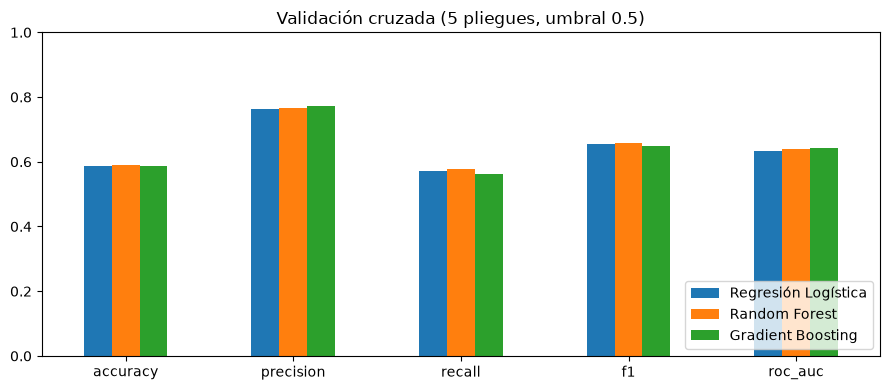

In [5]:
ax = cv[METRICAS].T.plot.bar(figsize=(9, 4), rot=0)
ax.set_ylim(0, 1); ax.set_title("Validación cruzada (5 pliegues, umbral 0.5)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

**Lectura:**
- Los tres modelos quedan **muy parejos** (ROC-AUC entre 0,63 y 0,64). Cuando modelos tan distintos dan lo mismo,
  el límite está en **la información de los datos** y no en el algoritmo.
- **Criterio de selección:** el mayor ROC-AUC promedio. Es independiente del umbral y mide qué tan bien el modelo *ordena*
  a los pacientes por riesgo. Si la diferencia fuera menor a 0,005, se elegiría el más simple.

Modelo elegido: Gradient Boosting


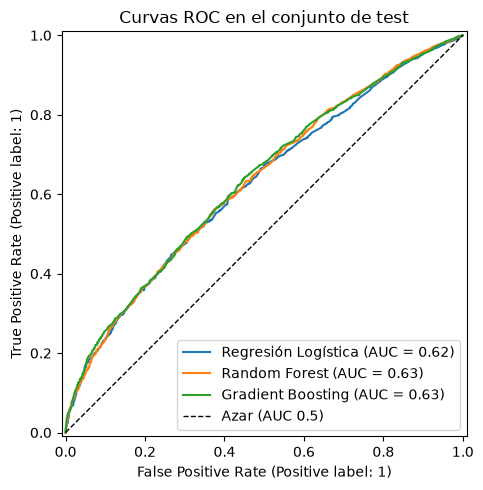

In [6]:
print("Modelo elegido:", artefacto["nombre_modelo"])
fig, ax = plt.subplots(figsize=(5.5, 5))
for nombre, modelo in ctx["modelos"].items():
    modelo.fit(ctx["X_train"], ctx["y_train"])
    RocCurveDisplay.from_estimator(modelo, ctx["X_test"], ctx["y_test"], name=nombre, ax=ax)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Azar (AUC 0.5)"); ax.legend(loc="lower right")
ax.set_title("Curvas ROC en el conjunto de test"); plt.tight_layout(); plt.show()

## 3. Umbral de decisión: priorizar el recall de dengue
Por defecto un clasificador dice "dengue" si la probabilidad es ≥ 0,5. Con ese umbral el recall es solo ~55 %:
**se escaparía casi la mitad de los casos de dengue**. En salud pública un falso negativo (mandar a casa a
alguien con dengue) es más grave que un falso positivo (pedir un examen de más).

**Regla usada:** el umbral **más alto** que logre **recall ≥ 80 %**, calculado con predicciones *fuera de pliegue* del
conjunto de entrenamiento (nunca con el test).

¿Por qué no maximizar F2 o bajar el umbral a 0? Con 68 % de positivos, un "modelo" que diga *dengue* a todo el mundo
tiene recall 100 % y F2 ≈ 0,91, pero no sirve para nada. La regla de recall mínimo evita esa trampa.

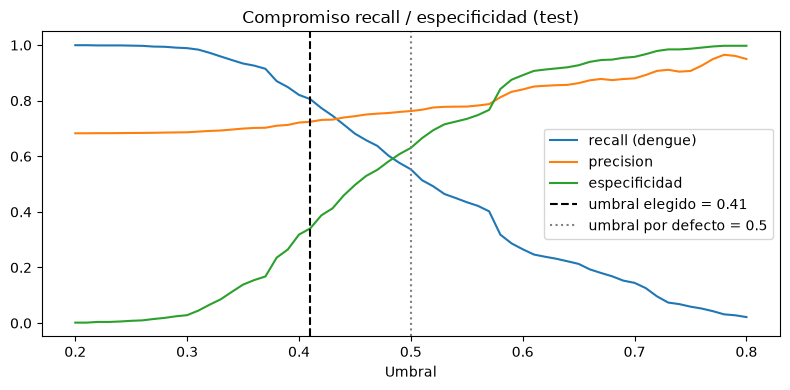

In [7]:
modelo = ctx["modelos"][artefacto["nombre_modelo"]]
proba = modelo.predict_proba(ctx["X_test"])[:, 1]
umbrales = np.arange(0.2, 0.8, 0.01)
curvas = pd.DataFrame({
    "recall (dengue)": [recall_score(ctx["y_test"], proba >= u) for u in umbrales],
    "precision": [precision_score(ctx["y_test"], proba >= u, zero_division=0) for u in umbrales],
    "especificidad": [recall_score(1 - ctx["y_test"], proba < u) for u in umbrales],
}, index=umbrales)
ax = curvas.plot(figsize=(8, 4))
ax.axvline(artefacto["umbral"], color="k", ls="--", label=f"umbral elegido = {artefacto['umbral']}")
ax.axvline(0.5, color="gray", ls=":", label="umbral por defecto = 0.5")
ax.set_xlabel("Umbral"); ax.set_title("Compromiso recall / especificidad (test)"); ax.legend()
plt.tight_layout(); plt.show()

## 4. Resultados finales en el conjunto de test (20 % nunca visto)

In [8]:
filas = ["accuracy", "precision", "recall", "especificidad", "f1", "roc_auc"]
pd.DataFrame({
    f"umbral elegido ({artefacto['umbral']})": {k: artefacto["metricas_test"][k] for k in filas},
    "umbral 0.5": {k: artefacto["metricas_test_umbral_05"][k] for k in filas},
})

,umbral elegido (0.41),umbral 0.5
accuracy,0.658,0.578
precision,0.724,0.763
recall,0.806,0.553
especificidad,0.340,0.630
f1,0.763,0.641
roc_auc,0.634,0.634


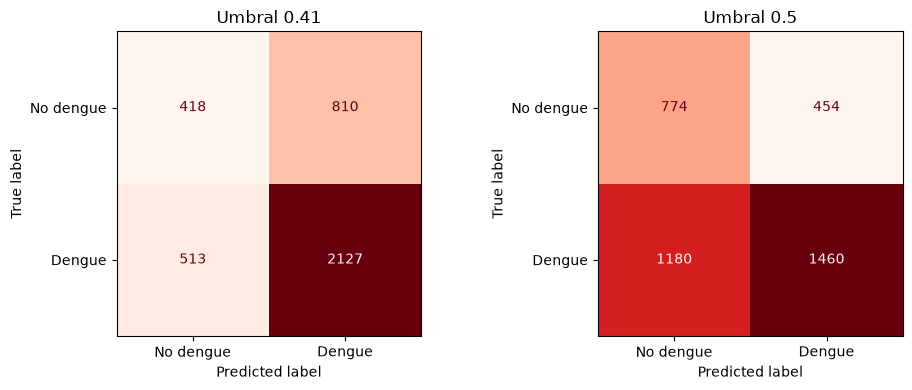

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (titulo, clave) in zip(axes, [(f"Umbral {artefacto['umbral']}", "metricas_test"), ("Umbral 0.5", "metricas_test_umbral_05")]):
    ConfusionMatrixDisplay(np.array(artefacto[clave]["matriz_confusion"]),
                           display_labels=["No dengue", "Dengue"]).plot(ax=ax, cmap="Reds", colorbar=False)
    ax.set_title(titulo)
plt.tight_layout(); plt.show()

**Lectura de la matriz de confusión (umbral elegido):**
- Se detecta ~**81 % de los dengues reales** (verdaderos positivos), contra ~55 % con el umbral 0,5.
- El costo: muchos falsos positivos. Solo ~1 de cada 3 pacientes sin dengue queda bien clasificado (especificidad ≈ 0,34).
- **Interpretación correcta:** es una herramienta de **tamizaje** ("vale la pena hacer la prueba de dengue"),
  **no de diagnóstico**. Esto coincide con el aviso obligatorio de la app.

## 5. Importancia de las variables
**Importancia por permutación:** se desordena al azar una variable en el test y se mide cuánto cae el ROC-AUC.
Si cae mucho, el modelo depende de esa variable. Sirve igual para cualquier modelo y trabaja sobre las variables
originales (edad como un todo, no cada columna one-hot por separado).

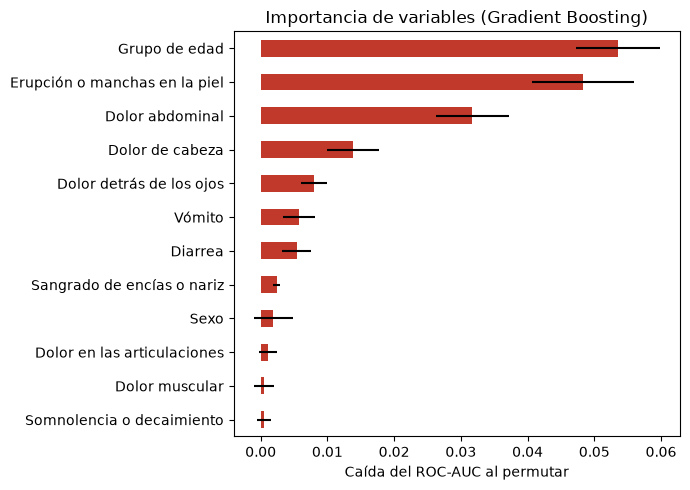

In [10]:
imp = pd.DataFrame(artefacto["importancia"]).sort_values("importancia")
ax = imp.plot.barh(x="nombre", y="importancia", xerr="std", legend=False, figsize=(7, 5), color="#c0392b")
ax.set_xlabel("Caída del ROC-AUC al permutar"); ax.set_ylabel("")
ax.set_title(f"Importancia de variables ({artefacto['nombre_modelo']})")
plt.tight_layout(); plt.show()

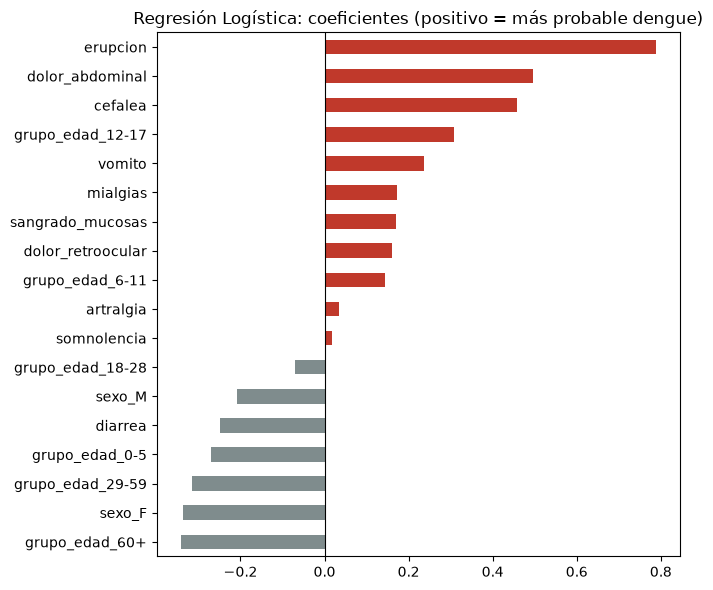

In [11]:
# Complemento interpretable: coeficientes de la Regresión Logística (signo = dirección del efecto)
lr = ctx["modelos"]["Regresión Logística"]
nombres = lr.named_steps["prep"].get_feature_names_out()
coef = pd.Series(lr.named_steps["clf"].coef_[0], index=[n.split("__")[1] for n in nombres])
coef.sort_values().plot.barh(figsize=(7, 6), color=np.where(coef.sort_values() > 0, "#c0392b", "#7f8c8d"))
plt.axvline(0, color="k", lw=0.8); plt.title("Regresión Logística: coeficientes (positivo = más probable dengue)")
plt.tight_layout(); plt.show()

**Lectura:** las variables que más aportan son el **grupo de edad**, la **erupción en la piel** y el **dolor abdominal**,
seguidas de la cefalea y el dolor retro-ocular. Es coherente con la Fase 1 y con la descripción clínica del dengue.
El dolor muscular, el dolor articular y la somnolencia casi no aportan, porque también aparecen en las otras virosis.

## 6. Validación temporal (prueba de robustez)
La partición aleatoria mezcla casos de todos los años. Aquí se prueba si el modelo funciona en un **período que no vio**.

In [12]:
pd.DataFrame(artefacto["validacion_temporal"])

,escenario,n_train,n_test,prevalencia_test,roc_auc
0,"Entrena 2024, evalúa 2023",15177,3023,0.663,0.626
1,"Entrena 2023-2024, evalúa 2025-2026",18200,1140,0.205,0.506


**Lectura (limitación importante):**
- Entrenado con 2024 y evaluado en 2023, el ROC-AUC se mantiene (~0,63). La señal es real y estable entre esos años.
- En **2025–2026** el ROC-AUC baja a ~0,50 (azar). En ese período post-epidemia hay muy pocos dengues confirmados
  (~20 %), y la relación entre síntomas y diagnóstico desaparece o se invierte. Las causas probables son otras
  virosis circulando con síntomas parecidos y casos todavía sin actualizar en SIVIGILA.
- **Conclusión:** el modelo refleja el patrón de 2023–2024 y **debería reentrenarse periódicamente** con datos nuevos.

## 7. Modelo guardado
`python -m src.train` guarda en `models/modelo.pkl` un diccionario con:
- `modelo`: el pipeline completo (imputación + one-hot + clasificador), **reentrenado con todos los datos**.
  Las métricas reportadas son las del test, que el modelo no había visto.
- `features`, `umbral`, `grupos_edad`, `nombres_sintomas`: lo que la app web necesita para construir el formulario.
- Métricas, importancia y versión de scikit-learn, para la página "Acerca del modelo".

También guarda `models/metricas.json`, una versión legible sin el modelo.

## 8. Conclusiones para la sustentación
1. Con solo síntomas reportables se logra un **ROC-AUC ≈ 0,63–0,64**: mejor que el azar, pero modesto. Es lo esperado,
   porque **el dengue se confirma con laboratorio justamente porque los síntomas no bastan**.
2. Los tres algoritmos rinden igual, así que el límite está en los datos, no en el modelo.
3. El umbral se ajustó para detectar **~80 % de los dengues**, a costa de falsas alarmas. Es adecuado para **tamizaje**.
4. Limitaciones: edad solo por rangos, datos de un municipio y deriva temporal en 2025–2026.